# 05_tuning_optuna_v3.ipynb

## 목적
RandomizedSearchCV의 한계(무작위 탐색)를 보완하기 위해 **Optuna 베이지안 최적화**를 적용합니다.
이전 탐색 결과를 학습하여 좋은 파라미터 구간을 집중적으로 탐색합니다.

## 실험 설계
- 데이터: 30% 샘플링 (stratify 유지)
- n_trials: 30 (RandomizedSearchCV n_iter=20 대비 베이지안 탐색)
- cv: 2
- 최적 파라미터로 전체 데이터 재학습

## 목차
1. 환경 세팅 및 데이터 로드
2. 30% 샘플링
3. Optuna 튜닝 (LightGBM)
4. Optuna 튜닝 (XGBoost)
5. 전체 데이터로 최종 모델 학습 및 평가
6. RandomizedSearchCV 대비 비교
7. 결과 저장


### 1. 환경 세팅 및 데이터 로드

In [ ]:
# optuna 설치
# !pip install optuna

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import xgboost as xgb
import optuna
import time, os

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import (
    accuracy_score, roc_auc_score, f1_score,
    confusion_matrix, roc_curve, classification_report
)

# Optuna 로그 레벨 낮추기 (출력 간결하게)
optuna.logging.set_verbosity(optuna.logging.WARNING)

plt.rc('font', family='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid')
pd.options.display.float_format = '{:.4f}'.format


임포트 완료


c:\workspace\2026project\customer_churn\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [8]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# Windows 한글 폰트 설정
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 설정 확인
print(f'폰트: {plt.rcParams["font.family"]}')

폰트: ['Malgun Gothic']


In [2]:
X_train = pd.read_csv('../data/processed/X_train_v3.csv')
X_val   = pd.read_csv('../data/processed/X_val_v3.csv')
y_train = pd.read_csv('../data/processed/y_train_v3.csv').squeeze()
y_val   = pd.read_csv('../data/processed/y_val_v3.csv').squeeze()

print(f'X_train: {X_train.shape}, X_val: {X_val.shape}')
print(f'y_train 이탈률: {y_train.mean():.4f}')

# v3 베이스라인 AUC 로드 (비교용)
try:
    v3_baseline = pd.read_csv('../results/baseline_comparison_v3.csv')
    print('\n--- v3 베이스라인 AUC (비교 기준) ---')
    print(v3_baseline[['model','auc_roc']].to_string(index=False))
except:
    print('베이스라인 결과 없음')


X_train: (914921, 54), X_val: (228731, 54)
y_train 이탈률: 0.5002
베이스라인 결과 없음


## 2. 30% 샘플링

In [3]:
X_sample, _, y_sample, _ = train_test_split(
    X_train, y_train,
    train_size=0.3,
    random_state=42,
    stratify=y_train
)

print(f'샘플 크기: {X_sample.shape} ({len(X_sample)/len(X_train)*100:.0f}%)')
print(f'샘플 이탈률: {y_sample.mean():.4f}')


샘플 크기: (274476, 54) (30%)
샘플 이탈률: 0.5002


## 3. Optuna 튜닝 — LightGBM

Optuna는 각 trial 결과를 학습하여 다음 탐색 방향을 결정합니다.
초반에는 넓게 탐색하다가 후반으로 갈수록 좋은 파라미터 구간에 집중합니다.


In [4]:
def lgbm_objective(trial):
    params = {
        'num_leaves'        : trial.suggest_int('num_leaves', 31, 255),
        'max_depth'         : trial.suggest_int('max_depth', -1, 20),
        'learning_rate'     : trial.suggest_float('learning_rate', 0.01, 0.15, log=True),
        'n_estimators'      : trial.suggest_int('n_estimators', 100, 500),
        'subsample'         : trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree'  : trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'min_child_samples' : trial.suggest_int('min_child_samples', 10, 100),
        'reg_alpha'         : trial.suggest_float('reg_alpha', 1e-8, 1.0, log=True),
        'reg_lambda'        : trial.suggest_float('reg_lambda', 1e-8, 1.0, log=True),
        'random_state'      : 42,
        'n_jobs'            : -1,
        'verbose'           : -1,
    }
    model = lgb.LGBMClassifier(**params)
    score = cross_val_score(
        model, X_sample, y_sample,
        cv=2, scoring='roc_auc', n_jobs=-1
    ).mean()
    return score

print('LightGBM Optuna 튜닝 시작...')
start = time.time()

lgbm_study = optuna.create_study(direction='maximize')
lgbm_study.optimize(lgbm_objective, n_trials=30, show_progress_bar=True)

lgbm_tuning_time = time.time() - start
lgbm_best_params = lgbm_study.best_params
lgbm_best_cv_auc = lgbm_study.best_value

print(f'\n튜닝 완료 ({lgbm_tuning_time:.1f}초)')
print(f'최적 CV AUC: {lgbm_best_cv_auc:.4f}')
print('최적 파라미터:')
print(lgbm_best_params)


LightGBM Optuna 튜닝 시작...


Best trial: 22. Best value: 0.846277: 100%|██████████| 30/30 [03:33<00:00,  7.12s/it]


튜닝 완료 (213.5초)
최적 CV AUC: 0.8463
최적 파라미터:
{'num_leaves': 86, 'max_depth': 17, 'learning_rate': 0.014206155350099007, 'n_estimators': 445, 'subsample': 0.8546868744478684, 'colsample_bytree': 0.6545032825808916, 'min_child_samples': 81, 'reg_alpha': 2.5414374921283707e-05, 'reg_lambda': 1.1148311865898095e-07}


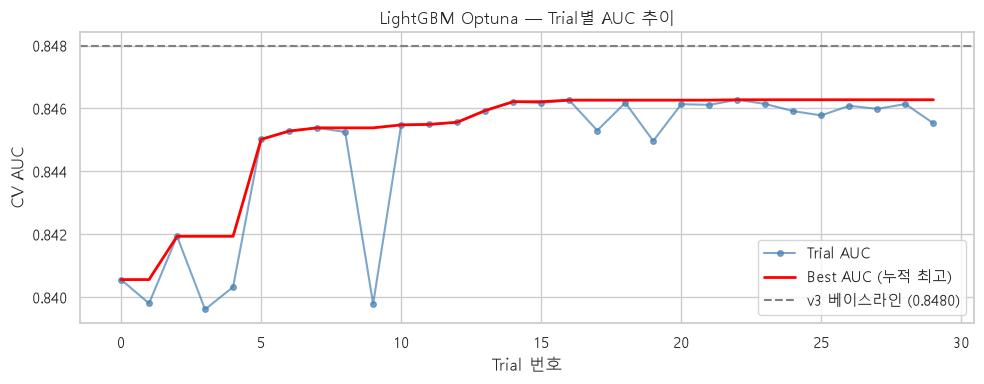

In [10]:
# 튜닝 과정 시각화 — trial별 AUC 추이
trial_aucs = [t.value for t in lgbm_study.trials]

plt.figure(figsize=(10, 4))
plt.plot(trial_aucs, marker='o', markersize=4, color='steelblue', alpha=0.7, label='Trial AUC')
plt.plot(np.maximum.accumulate(trial_aucs), color='red', lw=2, label='Best AUC (누적 최고)')
plt.axhline(y=0.8480, color='gray', linestyle='--', label='v3 베이스라인 (0.8480)')
plt.title('LightGBM Optuna — Trial별 AUC 추이')
plt.xlabel('Trial 번호')
plt.ylabel('CV AUC')
plt.legend()
plt.tight_layout()
plt.show()


## 4. Optuna 튜닝 — XGBoost

In [6]:
def xgb_objective(trial):
    params = {
        'max_depth'        : trial.suggest_int('max_depth', 3, 12),
        'learning_rate'    : trial.suggest_float('learning_rate', 0.01, 0.15, log=True),
        'n_estimators'     : trial.suggest_int('n_estimators', 100, 500),
        'subsample'        : trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree' : trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'min_child_weight' : trial.suggest_int('min_child_weight', 1, 20),
        'reg_alpha'        : trial.suggest_float('reg_alpha', 1e-8, 1.0, log=True),
        'reg_lambda'       : trial.suggest_float('reg_lambda', 1e-8, 1.0, log=True),
        'random_state'     : 42,
        'n_jobs'           : -1,
        'verbosity'        : 0,
        'eval_metric'      : 'auc',
        'use_label_encoder': False,
    }
    model = xgb.XGBClassifier(**params)
    score = cross_val_score(
        model, X_sample, y_sample,
        cv=2, scoring='roc_auc', n_jobs=-1
    ).mean()
    return score

print('XGBoost Optuna 튜닝 시작...')
start = time.time()

xgb_study = optuna.create_study(direction='maximize')
xgb_study.optimize(xgb_objective, n_trials=30, show_progress_bar=True)

xgb_tuning_time = time.time() - start
xgb_best_params = xgb_study.best_params
xgb_best_cv_auc = xgb_study.best_value

print(f'\n튜닝 완료 ({xgb_tuning_time:.1f}초)')
print(f'최적 CV AUC: {xgb_best_cv_auc:.4f}')
print('최적 파라미터:')
print(xgb_best_params)


XGBoost Optuna 튜닝 시작...


Best trial: 27. Best value: 0.846243: 100%|██████████| 30/30 [06:38<00:00, 13.29s/it]


튜닝 완료 (398.8초)
최적 CV AUC: 0.8462
최적 파라미터:
{'max_depth': 6, 'learning_rate': 0.034694365286812696, 'n_estimators': 464, 'subsample': 0.7568691027773513, 'colsample_bytree': 0.6125425821691814, 'min_child_weight': 14, 'reg_alpha': 3.7290884040421465e-05, 'reg_lambda': 1.1819011948978045e-05}


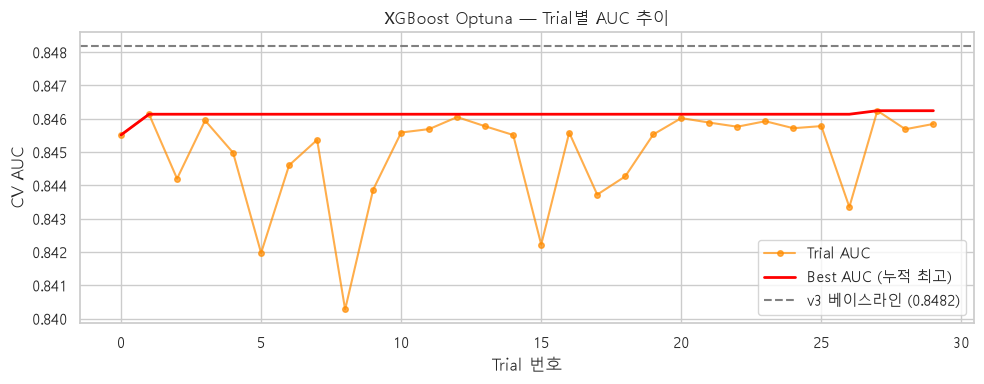

In [9]:
# XGBoost 튜닝 과정 시각화
trial_aucs_xgb = [t.value for t in xgb_study.trials]

plt.figure(figsize=(10, 4))
plt.plot(trial_aucs_xgb, marker='o', markersize=4, color='darkorange', alpha=0.7, label='Trial AUC')
plt.plot(np.maximum.accumulate(trial_aucs_xgb), color='red', lw=2, label='Best AUC (누적 최고)')
plt.axhline(y=0.8482, color='gray', linestyle='--', label='v3 베이스라인 (0.8482)')
plt.title('XGBoost Optuna — Trial별 AUC 추이')
plt.xlabel('Trial 번호')
plt.ylabel('CV AUC')
plt.legend()
plt.tight_layout()
plt.show()


## 5. 전체 데이터로 최종 모델 학습 및 평가

30% 샘플로 찾은 최적 파라미터를 전체 Train 데이터(100%)로 재학습합니다.


In [ ]:
# LightGBM 최종 학습
final_lgbm = lgb.LGBMClassifier(
    **lgbm_best_params, random_state=42, n_jobs=-1, verbose=-1
)
start = time.time()
final_lgbm.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(-1)]
)
lgbm_train_time = time.time() - start

lgbm_pred  = final_lgbm.predict(X_val)
lgbm_proba = final_lgbm.predict_proba(X_val)[:, 1]
lgbm_acc   = accuracy_score(y_val, lgbm_pred)
lgbm_auc   = roc_auc_score(y_val, lgbm_proba)
lgbm_f1    = f1_score(y_val, lgbm_pred)

print('--- LightGBM Optuna 최종 성능 ---')
print(f'Accuracy : {lgbm_acc:.4f}')
print(f'AUC-ROC  : {lgbm_auc:.4f}')
print(f'F1-Score : {lgbm_f1:.4f}')
print(f'학습 시간 : {lgbm_train_time:.1f}초')


In [ ]:
# XGBoost 최종 학습
final_xgb = xgb.XGBClassifier(
    **xgb_best_params, random_state=42, n_jobs=-1, verbosity=0,
    eval_metric='auc', use_label_encoder=False, early_stopping_rounds=50
)
start = time.time()
final_xgb.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
xgb_train_time = time.time() - start

xgb_pred  = final_xgb.predict(X_val)
xgb_proba = final_xgb.predict_proba(X_val)[:, 1]
xgb_acc   = accuracy_score(y_val, xgb_pred)
xgb_auc   = roc_auc_score(y_val, xgb_proba)
xgb_f1    = f1_score(y_val, xgb_pred)

print('--- XGBoost Optuna 최종 성능 ---')
print(f'Accuracy : {xgb_acc:.4f}')
print(f'AUC-ROC  : {xgb_auc:.4f}')
print(f'F1-Score : {xgb_f1:.4f}')
print(f'학습 시간 : {xgb_train_time:.1f}초')


## 6. RandomizedSearchCV 대비 비교

In [ ]:
compare = pd.DataFrame([
    {'방법': 'v3 베이스라인',          '모델': 'LightGBM', 'AUC': 0.8480, '비고': '기본 파라미터'},
    {'방법': 'RandomizedSearchCV',   '모델': 'LightGBM', 'AUC': 0.8477, '비고': 'n_iter=20, 30% 샘플'},
    {'방법': 'Optuna',               '모델': 'LightGBM', 'AUC': lgbm_auc, '비고': 'n_trials=30, 30% 샘플'},
    {'방법': 'v3 베이스라인',          '모델': 'XGBoost',  'AUC': 0.8482, '비고': '기본 파라미터'},
    {'방법': 'RandomizedSearchCV',   '모델': 'XGBoost',  'AUC': 0.8482, '비고': 'n_iter=20, 30% 샘플'},
    {'방법': 'Optuna',               '모델': 'XGBoost',  'AUC': xgb_auc, '비고': 'n_trials=30, 30% 샘플'},
])

print('--- 튜닝 방법별 AUC 비교 ---')
print(compare.to_string(index=False))


In [ ]:
# ROC Curve 비교
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (model_name, proba, color) in zip(axes, [
    ('LightGBM', lgbm_proba, 'steelblue'),
    ('XGBoost',  xgb_proba,  'darkorange')
]):
    fpr, tpr, _ = roc_curve(y_val, proba)
    auc_val = roc_auc_score(y_val, proba)
    ax.plot(fpr, tpr, color=color, lw=2, label=f'{model_name} Optuna (AUC={auc_val:.4f})')
    ax.plot([0,1],[0,1], linestyle='--', color='gray', label='Random Baseline')
    ax.set_title(f'{model_name} — Optuna 튜닝 ROC Curve')
    ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
    ax.legend()

plt.tight_layout()
plt.show()


In [ ]:
# 결론 자동 출력
best_auc = max(lgbm_auc, xgb_auc)
baseline_best = 0.8486  # v3 CatBoost 베이스라인
improvement = best_auc - baseline_best

print('=' * 50)
print('Optuna 튜닝 결론')
print('=' * 50)
print(f'v3 베이스라인 최고 AUC : {baseline_best:.4f} (CatBoost)')
print(f'Optuna 최고 AUC       : {best_auc:.4f}')
print(f'개선폭                : {improvement:+.4f}')
print()
if improvement < 0.003:
    print('→ Optuna 베이지안 최적화로도 유의미한 성능 개선이 없었습니다.')
    print('  이는 하이퍼파라미터 튜닝의 문제가 아니라,')
    print('  거래 이력 기반 피처 자체의 정보량 한계임을 강하게 시사합니다.')
else:
    print('→ Optuna를 통해 유의미한 성능 개선이 확인되었습니다.')


## 7. 결과 저장

In [ ]:
os.makedirs('../results', exist_ok=True)

result = pd.DataFrame([
    {
        'model'        : 'LightGBM_optuna_v3',
        'accuracy'     : round(lgbm_acc, 4),
        'auc_roc'      : round(lgbm_auc, 4),
        'f1_score'     : round(lgbm_f1, 4),
        'train_time'   : round(lgbm_train_time, 1),
        'tuning_time'  : round(lgbm_tuning_time, 1),
        'n_trials'     : 30,
        'best_cv_auc'  : round(lgbm_best_cv_auc, 4),
    },
    {
        'model'        : 'XGBoost_optuna_v3',
        'accuracy'     : round(xgb_acc, 4),
        'auc_roc'      : round(xgb_auc, 4),
        'f1_score'     : round(xgb_f1, 4),
        'train_time'   : round(xgb_train_time, 1),
        'tuning_time'  : round(xgb_tuning_time, 1),
        'n_trials'     : 30,
        'best_cv_auc'  : round(xgb_best_cv_auc, 4),
    }
])

result.to_csv('../results/optuna_result_v3.csv', index=False)
print('결과 저장 완료: ../results/optuna_result_v3.csv')
print(result.to_string(index=False))
